# 02 · Variação entre eletrodos, na mesma gota e entre campanhas

O notebook 01 mostra a visão geral em valores absolutos. Aqui usamos as Figuras 24 a 26 da monografia (páginas impressas 82 a 84) para detalhar três níveis de variação do módulo da impedância |Z|.

Uma **aquisição técnica** corresponde a um arquivo de EIS. Uma **aplicação** corresponde a uma gota. Uma **campanha** reúne várias aplicações. Os arquivos disponíveis identificam as campanhas, sem datas de aquisição para comparar dias específicos.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D
from matplotlib.path import Path as MarkerPath
from matplotlib.ticker import ScalarFormatter
from matplotlib.transforms import Affine2D

RAIZ = Path.cwd()
if not (RAIZ / 'Medicoes_EIS_Por_Dispositivo').is_dir():
    RAIZ = RAIZ.parent
PASTA = RAIZ / 'Medicoes_EIS_Por_Dispositivo'
assert PASTA.is_dir(), 'Abra o notebook na pasta dispositivo.'
PASTA_FIGURAS = RAIZ / 'imagens_prontas'
PASTA_FIGURAS.mkdir(exist_ok=True)

AZUL, TERRACOTA, VERDE, CINZA = '#0079B7', '#BF5A3C', '#276445', '#444B60'
QUADRADO_VAZADO = MarkerPath.make_compound_path(
    MarkerPath.unit_rectangle().transformed(Affine2D().translate(-.5, -.5)),
    MarkerPath.unit_circle().transformed(Affine2D().scale(.24, -.24)),
)
LINHAGENS = {'MCF10A': (AZUL, 's'), 'HCC1806': (TERRACOTA, QUADRADO_VAZADO)}
BANDAS = ['1–10', '10–100', '100–1k', '1k–10k', '10k–100k', '100k–1M']
BORDAS = [1, 10, 100, 1_000, 10_000, 100_000, np.nextafter(1e6, np.inf)]

plt.rcParams.update({
    'font.family': 'Times New Roman', 'pdf.fonttype': 42,
    'mathtext.fontset': 'custom', 'mathtext.rm': 'Times New Roman',
    'mathtext.it': 'Times New Roman:italic', 'mathtext.bf': 'Times New Roman:bold',
    'mathtext.bfit': 'Times New Roman:italic:bold',
    'figure.dpi': 120, 'font.size': 11,
    'xtick.labelsize': 11, 'ytick.labelsize': 11,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'figure.titlesize': 14,
    'legend.fontsize': 11, 'legend.title_fontsize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'axes.grid.axis': 'y', 'axes.axisbelow': True, 'grid.color': '#D8DEE3',
    'grid.alpha': .7, 'axes.edgecolor': '#ABB5BD', 'figure.constrained_layout.use': True,
})


def ler_modulo(arquivo):
    t = pd.read_csv(arquivo, encoding='utf-8-sig')
    freq = t['Frequency (Hz)'].to_numpy(dtype=float)
    z = t['Z (Ω)'].to_numpy(dtype=float)
    assert np.isfinite(freq).all() and np.isfinite(z).all(), arquivo
    assert (freq > 0).all() and (z > 0).all() and len(np.unique(freq)) == len(freq), arquivo
    return pd.Series(z, index=pd.Index(freq, name='frequencia_hz'),
                     name='modulo_ohm').sort_index()

## 1. Entre eletrodos · Figura 24 ampliada

Mantemos E03, E04, E05 e E10 e o rótulo nominal 10e8 dos arquivos, apresentado como 10⁸ partículas/mL na Figura 24. A cada curva de VEs acrescentamos o controle processado da mesma origem e condição nominal, em uma linha de painéis própria. Cada curva representa uma aplicação.

O gráfico mostra a média por banda de 100 × (|Z| do material / |Z| do PBS − 1), calculado primeiro por frequência. As referências de PBS foram reconstruídas pelos nomes dos arquivos e conferidas visualmente com o traçado das VEs na Figura 24. Os controles usam o mesmo PBS da origem correspondente. O pareamento está na tabela para conferência com o registro experimental. A escala dos controles é simétrica logarítmica, com trecho linear até ±25%, para acomodar o valor elevado de E10.

A segunda versão mantém as curvas normalizadas de VEs na linha de cima. Na linha de baixo, cada curva mostra o |Z| do PBS de referência em ohms, em escala logarítmica. As cores identificam a linhagem à qual cada referência foi pareada.

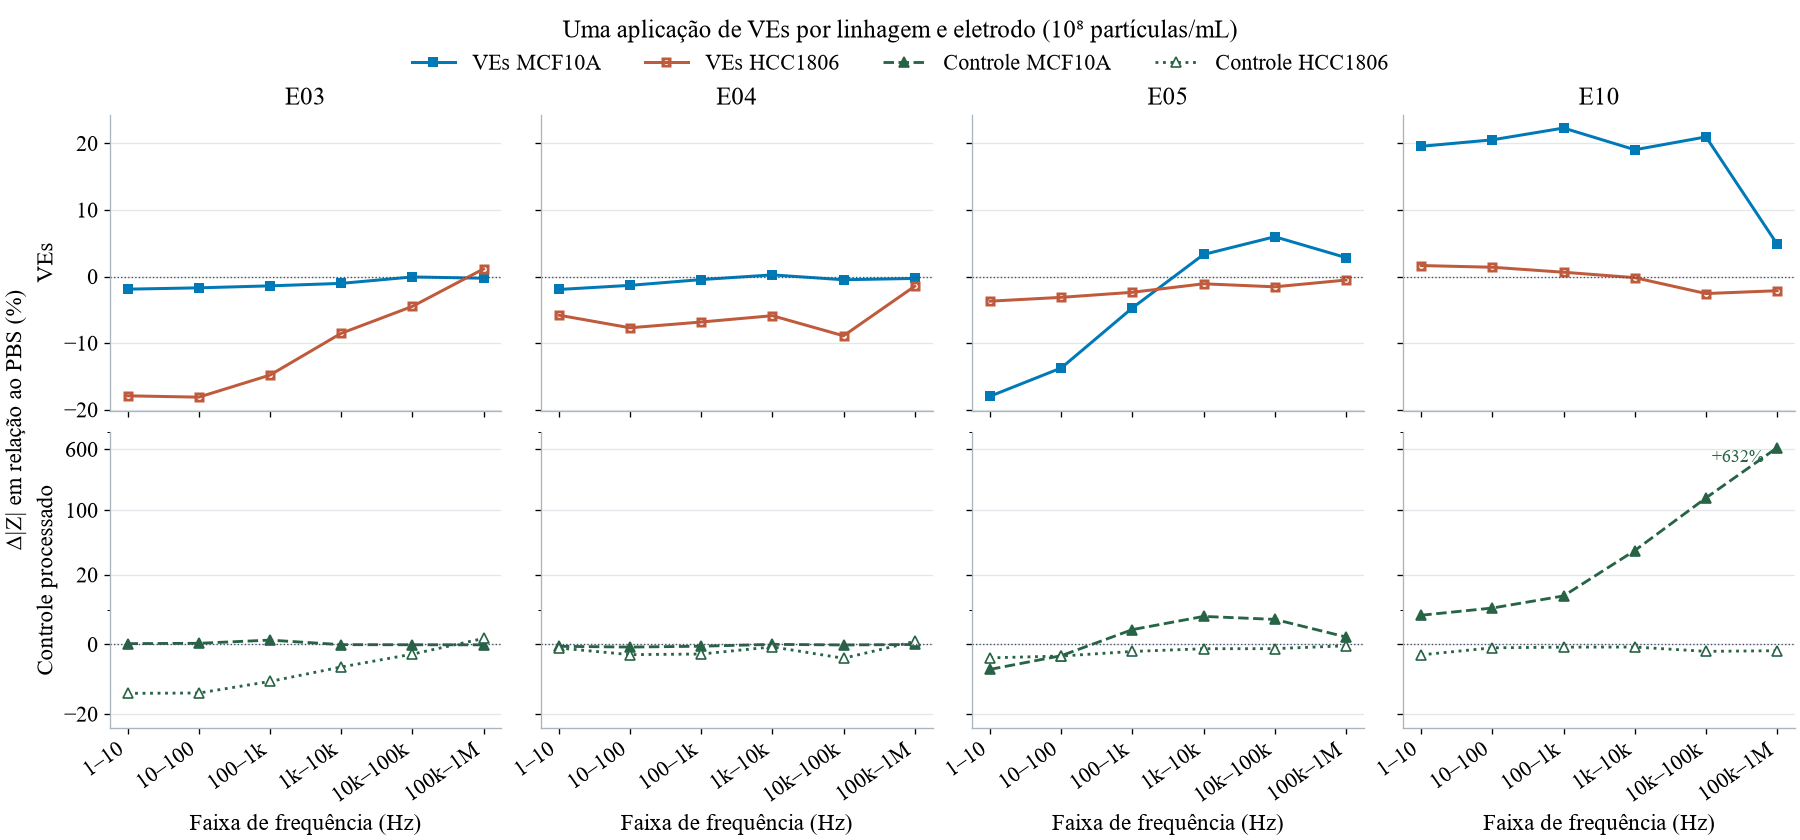

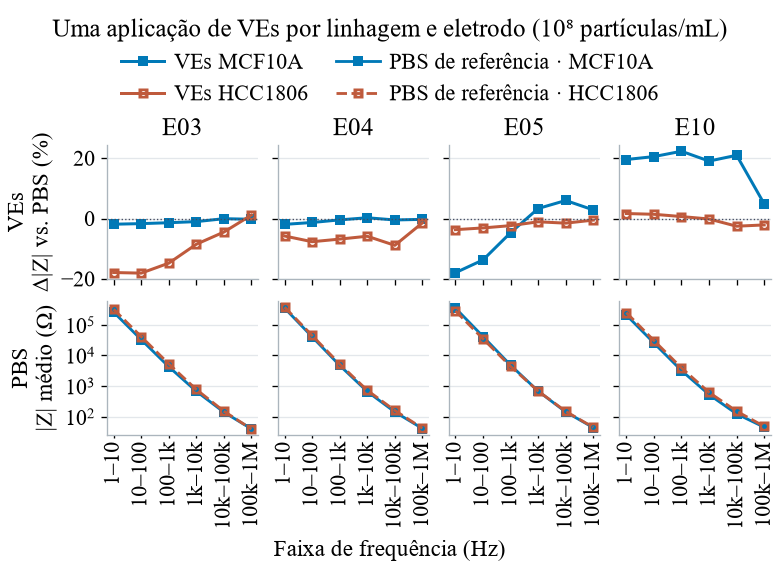

,Eletrodo,Linhagem,Material,Arquivo,PBS
0,E03,MCF10A,VEs,VEs_10e8_MCF_eletrodo3.txt,PBS_Intermediario_MCF_eletrodo3.txt
1,E03,MCF10A,Controle,Controle_10e8_MCF_eletrodo3.txt,PBS_Intermediario_MCF_eletrodo3.txt
2,E03,HCC1806,VEs,VEs_10e8_HCC_eletrodo3.txt,PBS_inicial_HCC_eletrodo3.txt
3,E03,HCC1806,Controle,Controle_10e8_HCC_eletrodo3.txt,PBS_inicial_HCC_eletrodo3.txt
4,E04,MCF10A,VEs,VEs_10e8_MCF_eletrodo4.txt,PBS_Intermediário_MCF_eletrodo4.txt
5,E04,MCF10A,Controle,Controle_10e8_MCF_eletrodo4.txt,PBS_Intermediário_MCF_eletrodo4.txt
6,E04,HCC1806,VEs,VEs_10e8_HCC_eletrodo4.txt,PBS_inicial_HCC_eletrodo4.txt
7,E04,HCC1806,Controle,Controle_10e8_HCC_eletrodo4.txt,PBS_inicial_HCC_eletrodo4.txt
8,E05,MCF10A,VEs,VEs_10e8_MCF10A_eletrodo5.txt,PBS_inicial_MCF10A_eletrodo5.txt
9,E05,MCF10A,Controle,Controle_10e8_MCF10A_eletrodo5_.txt,PBS_inicial_MCF10A_eletrodo5.txt


In [2]:
with plt.rc_context({'font.family': 'Times New Roman', 'pdf.fonttype': 42,
        'axes.titlesize': 15, 'axes.labelsize': 14, 'figure.labelsize': 14,
        'xtick.labelsize': 13, 'ytick.labelsize': 13, 'legend.fontsize': 13,
        'legend.title_fontsize': 15}):
    referencias = {
        'E03': ('PBS_Intermediario_MCF_eletrodo3.txt', 'PBS_inicial_HCC_eletrodo3.txt'),
        'E04': ('PBS_Intermediário_MCF_eletrodo4.txt', 'PBS_inicial_HCC_eletrodo4.txt'),
        'E05': ('PBS_inicial_MCF10A_eletrodo5.txt', 'PBS_intermediario_HCC_eletrodo5.txt'),
        'E10': ('Controle_PBS_MEDIDA2_LOGO_EM_SEGUIDA_MCF10A_eletrodo_10(1).txt',
                'Controle_PBS_HCC__eletrodo_10(1).txt'),
    }
    fig, axs = plt.subplots(2, 4, figsize=(15, 7), sharex=True, sharey='row')
    fig_pbs, axs_pbs = plt.subplots(2, 4, figsize=(16.5 / 2.54, 12.0 / 2.54), sharex=True, sharey='row')
    titulo_amostragem = 'Uma aplicação de VEs por linhagem e eletrodo (10⁸ partículas/mL)'
    pares = []
    for col, (eletrodo, pbs_nomes) in enumerate(referencias.items()):
        pasta = PASTA / eletrodo
        arquivos = list(pasta.glob('*.txt'))
        for (linhagem, (cor, marcador)), nome_pbs in zip(LINHAGENS.items(), pbs_nomes):
            linh = 'MCF' if linhagem == 'MCF10A' else 'HCC'
            pbs = ler_modulo(pasta / nome_pbs)
            faixas_pbs = pd.cut(pbs.index, BORDAS, labels=BANDAS, right=False)
            perfil_pbs = pbs.groupby(faixas_pbs, observed=False).mean()
            axs_pbs[1, col].plot(
                BANDAS, perfil_pbs, color=cor, marker=marcador, markeredgewidth=0,
                lw=1.7, ls='--' if linh == 'HCC' else '-', label=f'PBS de referência · {linhagem}',
            )
            for row, (prefixo, material) in enumerate([('VES', 'VEs'), ('CONTROLE', 'Controle')]):
                arquivo, = [p for p in arquivos if p.name.upper().startswith(f'{prefixo}_10E8_{linh}')]
                espectro = ler_modulo(arquivo)
                assert espectro.index.equals(pbs.index), (arquivo, nome_pbs)
                delta = 100 * (espectro / pbs - 1)
                faixas = pd.cut(delta.index, BORDAS, labels=BANDAS, right=False)
                perfil = delta.groupby(faixas, observed=False).mean()
                assert perfil.notna().all(), arquivo
                ax = axs[row, col]
                if row == 0:
                    ax.plot(BANDAS, perfil, color=cor, marker=marcador, lw=1.8, markeredgewidth=0,
                            label=f'VEs {linhagem}')
                    axs_pbs[0, col].plot(BANDAS, perfil, color=cor, marker=marcador,
                                         lw=1.8, markeredgewidth=0, label=f'VEs {linhagem}')
                else:
                    ax.plot(BANDAS, perfil, color=VERDE, marker='^', lw=1.7,
                            ls='--' if linh == 'MCF' else ':',
                            mfc=VERDE if linh == 'MCF' else 'white', label=f'Controle {linhagem}')
                    if eletrodo == 'E10' and linh == 'MCF':
                        valor = perfil.iloc[-1]
                        ax.annotate(f'{valor:+.0f}%', (BANDAS[-1], valor), xytext=(-8, -1),
                                    textcoords='offset points', ha='right', va='top', color=VERDE)
                pares.append((eletrodo, linhagem, material, arquivo.name, nome_pbs))
        axs[0, col].set_title(eletrodo)
        axs_pbs[0, col].set_title(eletrodo)

    for ax in axs.flat:
        ax.axhline(0, color=CINZA, lw=.8, ls=':')
    for ax in axs[1]:
        ax.set_yscale('symlog', linthresh=25)
        ax.set_xticks(range(len(BANDAS)), BANDAS, rotation=35, ha='right')
        ax.set_xlabel('Faixa de frequência (Hz)')
    axs[1, 0].set_yticks([-20, 0, 20, 100, 600])
    axs[1, 0].set_ylim(-24, 1_000)
    axs[1, 0].yaxis.set_major_formatter(ScalarFormatter())
    axs[0, 0].set_ylabel('VEs')
    axs[1, 0].set_ylabel('Controle processado')
    fig.supylabel('Δ|Z| em relação ao PBS (%)')
    fig.legend(handles=axs[0, 0].lines[:2] + axs[1, 0].lines[:2],
               loc='outside upper center', ncol=4, frameon=False, title=titulo_amostragem)

    for ax in axs_pbs[0]:
        ax.axhline(0, color=CINZA, lw=.8, ls=':')
    for ax in axs_pbs[1]:
        ax.set_yscale('log')
        ax.set_xticks(range(len(BANDAS)), BANDAS, rotation=90)
        ax.tick_params(axis='x', length=2, pad=2)
    axs_pbs[1, 0].set_yticks([100, 1_000, 10_000, 100_000])
    fig_pbs.supxlabel('Faixa de frequência (Hz)')
    axs_pbs[0, 0].set_ylabel('VEs\nΔ|Z| vs. PBS (%)')
    axs_pbs[1, 0].set_ylabel('PBS\n|Z| médio (Ω)')
    fig_pbs.legend(handles=axs_pbs[0, 0].lines[:2] + axs_pbs[1, 0].lines,
                   loc='outside upper center', ncol=2, frameon=False, title=titulo_amostragem,
                   columnspacing=1.3, handletextpad=.45)
    fig_pbs.savefig(PASTA_FIGURAS / 'comparacao_espectral_com_pbs.pdf')
    plt.show()
    display(pd.DataFrame(pares, columns=['Eletrodo', 'Linhagem', 'Material', 'Arquivo', 'PBS']))

## 2. Na mesma gota · três aquisições técnicas no E7

O primeiro gráfico reúne as **30 gotas de VEs** em um único painel. Os dois gráficos usam os mesmos números de aplicação, de 01 a 30. A tabela após o mapa de calor relaciona os números aos códigos dos arquivos. Cada trio de pontos mostra as três leituras de uma gota, com zero na média das três. Um valor de +0,5% significa que aquela leitura ficou 0,5% acima da média da gota. As cores indicam as linhagens. Leituras 1, 2 e 3 identificam o arquivo-base e as variantes (1) e (2).

Usamos **100 kHz** como referência para dialogar com a Figura 26, que compara as campanhas nessa frequência. O mapa seguinte cobre as sete bandas adquiridas de 0,1 Hz a 1 MHz. Em cada banda, tiramos primeiro a média de |Z| das frequências para cada leitura. A cor de cada célula mostra a amplitude do trio, ou seja, 100 × (maior média − menor média) / média das três. Os intervalos excluem a borda superior, com inclusão de 1 MHz na última banda.

Para ver os três pontos de cada gota em outra banda, altere AREA_EXIBIDA na célula dos gráficos. O gráfico de CV mantém só as campanhas inicial e ampliada para comparação com a Figura 25. Cada ponto é a mediana dos CVs da gota entre 10 kHz e 1 MHz, e os traços indicam as medianas por campanha.

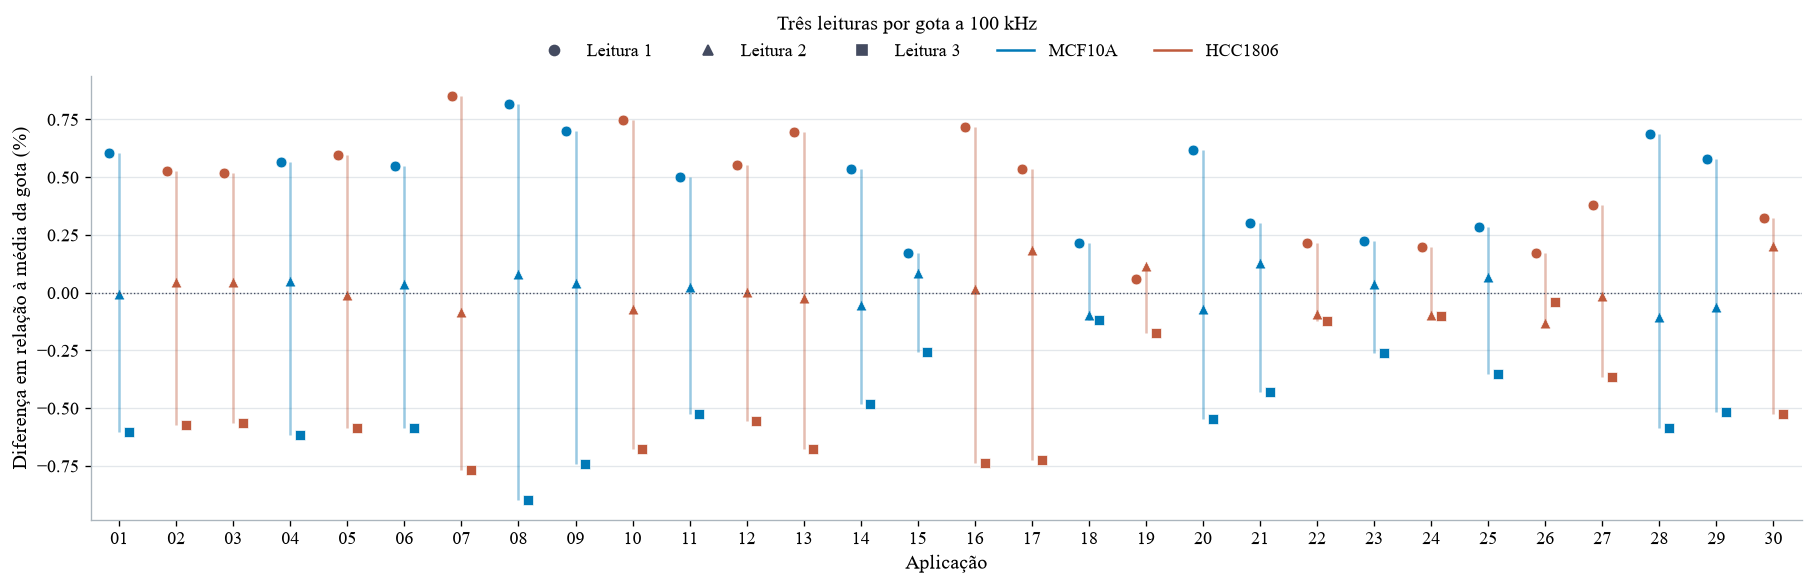

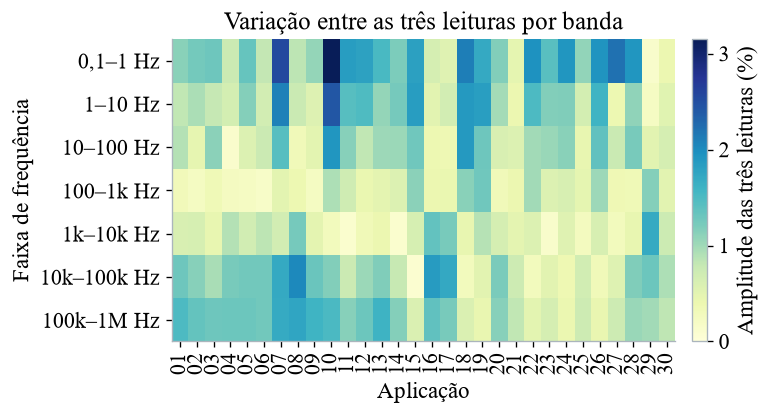

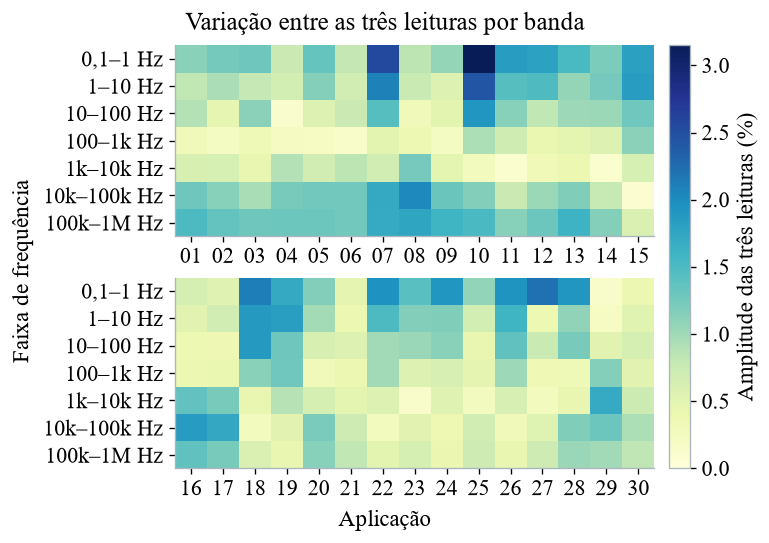

,Código nos arquivos,Campanha,Linhagem
Aplicação,,,
01,A02,Inicial,MCF10A
02,A04,Inicial,HCC1806
03,A07,Inicial,HCC1806
04,A08,Inicial,MCF10A
05,A09,Inicial,HCC1806
06,A11,Inicial,MCF10A
07,T01,T01–T08,HCC1806
08,T02,T01–T08,MCF10A
09,T03,T01–T08,MCF10A


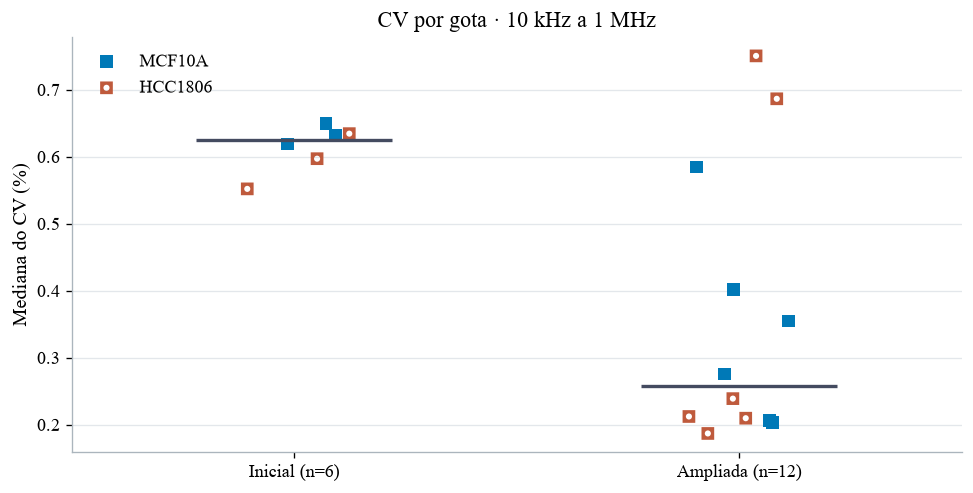

,gotas,mediana,minimo,maximo
etapa,,,,
Ampliada,12,0.257,0.187,0.75
Inicial,6,0.625,0.552,0.65


In [3]:
CAMPANHAS = {'01_Campanha_inicial': 'Inicial', '04_Treinamento_V2': 'Ampliada'}
ETAPAS_E07 = {
    '01_Campanha_inicial': 'Inicial',
    '03_T01-T08': 'T01–T08',
    '04_Treinamento_V2': 'Ampliada',
    '05_Validacao_V3': 'Validação',
}
LINHAGENS_T01_T08 = {
    'T01': 'HCC1806', 'T02': 'MCF10A', 'T03': 'MCF10A', 'T04': 'HCC1806',
    'T05': 'MCF10A', 'T06': 'HCC1806', 'T07': 'HCC1806', 'T08': 'MCF10A',
}
FREQ = 100_000
inventario = pd.read_csv(RAIZ / 'inventario.csv', encoding='utf-8-sig')
registros = inventario[
    (inventario.campanha.isin(ETAPAS_E07) & inventario.tipo.eq('VEs'))
    | (inventario.campanha.isin(ETAPAS_E07) & inventario.tipo.eq('PBS'))
].copy()
# O PBS local tem o mesmo número da aplicação, por exemplo A02 e P02.
registros['gota'] = registros.arquivo.str.extract(r'(?:^|_)([APT]\d{2})(?=_)')
registros = registros.dropna(subset=['gota'])
registros['leitura'] = registros.arquivo.str.extract(r'\(([12])\)\.txt$')[0].fillna('0').astype(int) + 1
registros['linhagem'] = registros.arquivo.str.extract(r'_(MCF|HCC)_')[0].map(
    {'MCF': 'MCF10A', 'HCC': 'HCC1806'}
)
teste = registros.campanha.eq('03_T01-T08')
registros.loc[teste, 'linhagem'] = registros.loc[teste, 'gota'].map(LINHAGENS_T01_T08)
registros['etapa'] = registros.campanha.map(ETAPAS_E07)
assert registros.loc[registros.tipo.eq('VEs'), 'linhagem'].notna().all()

espectros = []
for r in registros.itertuples(index=False):
    z = ler_modulo(PASTA / 'E07' / r.campanha / r.arquivo)
    espectros.append(z.reset_index().assign(
        etapa=r.etapa, gota=r.gota, leitura=r.leitura, tipo=r.tipo, linhagem=r.linhagem,
        arquivo=r.arquivo,
    ))
leituras = pd.concat(espectros, ignore_index=True)
chaves = ['etapa', 'gota', 'frequencia_hz']
ves = leituras[leituras.tipo.eq('VEs')].copy()
pbs = leituras[leituras.tipo.eq('PBS')].copy()
prefixo_ves = np.where(pbs.etapa.eq('T01–T08'), 'T', 'A')
pbs['gota'] = prefixo_ves + pbs.gota.str[1:]
for dados in (ves, pbs):
    triplicatas = dados.groupby(chaves).leitura.agg(['size', 'nunique'])
    assert triplicatas.eq(3).all().all()
    assert dados.groupby(['etapa', 'gota']).frequencia_hz.nunique().eq(71).all()
assert ves.groupby('etapa').gota.nunique().to_dict() == {
    'Inicial': 6, 'T01–T08': 8, 'Ampliada': 12, 'Validação': 4,
}
assert ves.arquivo.nunique() == 90

ves_comparacao = ves[ves.etapa.isin(CAMPANHAS.values())]
por_gota = ves_comparacao.groupby(chaves + ['linhagem'], as_index=False).agg(
    media=('modulo_ohm', 'mean'), desvio=('modulo_ohm', 'std'),
)
por_gota['cv_pct'] = 100 * por_gota.desvio / por_gota.media
cv = (por_gota[por_gota.frequencia_hz.between(10_000, 1_000_000)]
      .groupby(['etapa', 'gota', 'linhagem'], as_index=False).cv_pct.median())
BANDAS_E07 = [f'{faixa} Hz' for faixa in ['0,1–1', *BANDAS]]
bandas_leituras = ves.assign(banda=pd.cut(
    ves.frequencia_hz, [.1, *BORDAS], labels=BANDAS_E07, right=False,
))
assert bandas_leituras.banda.notna().all()
por_leitura_banda = (bandas_leituras.groupby(
    ['etapa', 'gota', 'linhagem', 'leitura', 'banda'], observed=True, as_index=False,
).modulo_ohm.mean())
assert len(por_leitura_banda) == 30 * 3 * len(BANDAS_E07)

# Use None para 100 kHz ou um rótulo de BANDAS_E07 para detalhar uma banda.
AREA_EXIBIDA = None

# Um índice único distingue aplicações com o mesmo código em campanhas diferentes.
ordem_aplicacoes = ves[['etapa', 'gota', 'linhagem']].drop_duplicates().copy()
ordem_aplicacoes['etapa'] = pd.Categorical(
    ordem_aplicacoes.etapa, categories=list(ETAPAS_E07.values()), ordered=True,
)
ordem_aplicacoes = ordem_aplicacoes.sort_values(['etapa', 'gota']).reset_index(drop=True)
ordem_aplicacoes['aplicacao'] = [f'{i:02d}' for i in range(1, len(ordem_aplicacoes) + 1)]
rotulos_aplicacoes = ordem_aplicacoes.aplicacao.to_list()
assert len(rotulos_aplicacoes) == 30


def plotar_triplicatas(faixa=None):
    if faixa is None:
        acq = ves[ves.frequencia_hz.eq(FREQ)].copy()
        titulo = 'Três leituras por gota a 100 kHz'
    else:
        if faixa not in BANDAS_E07:
            raise ValueError(f'Escolha uma banda de BANDAS_E07: {BANDAS_E07}')
        acq = por_leitura_banda[por_leitura_banda.banda.eq(faixa)].copy()
        titulo = f'Três leituras por gota · {faixa}'

    assert len(acq) == 90
    media = acq.groupby(['etapa', 'gota']).modulo_ohm.transform('mean')
    acq['desvio_pct'] = 100 * (acq.modulo_ohm / media - 1)

    fig, ax = plt.subplots(figsize=(15, 4.8))
    marcas = {1: ('o', -.17), 2: ('^', 0), 3: ('s', .17)}
    grupos = acq.groupby(['etapa', 'gota'])
    for x, aplicacao in enumerate(ordem_aplicacoes.itertuples(index=False)):
        grupo = grupos.get_group((aplicacao.etapa, aplicacao.gota))
        cor, _ = LINHAGENS[aplicacao.linhagem]
        ax.vlines(x, grupo.desvio_pct.min(), grupo.desvio_pct.max(), color=cor, alpha=.4)
        for r in grupo.itertuples():
            marcador, dx = marcas[r.leitura]
            ax.scatter(x + dx, r.desvio_pct, s=42, color=cor, marker=marcador,
                       edgecolors='white', linewidths=.4)
    ax.axhline(0, color=CINZA, lw=.8, ls=':')
    ax.set_xlim(-.5, len(rotulos_aplicacoes) - .5)
    ax.set_xticks(range(len(rotulos_aplicacoes)), rotulos_aplicacoes)
    ax.set(xlabel='Aplicação', ylabel='Diferença em relação à média da gota (%)')

    legenda = [
        Line2D([], [], marker=marcador, ls='', color=CINZA, label=f'Leitura {numero}')
        for numero, (marcador, _) in marcas.items()
    ] + [
        Line2D([], [], color=cor, label=linhagem)
        for linhagem, (cor, _) in LINHAGENS.items()
    ]
    fig.legend(handles=legenda, loc='outside upper center', ncol=len(legenda),
               frameon=False, title=titulo)
    plt.show()


plotar_triplicatas(AREA_EXIBIDA)

amplitudes = por_leitura_banda.groupby(['etapa', 'gota', 'banda'], observed=True).modulo_ohm.agg(
    ['min', 'max', 'mean'],
)
amplitudes['amplitude_pct'] = 100 * (amplitudes['max'] - amplitudes['min']) / amplitudes['mean']
mapa = amplitudes.amplitude_pct.unstack('banda').reindex(columns=BANDAS_E07)
assert mapa.shape == (30, 7) and mapa.notna().all().all()

ordem_mapa = pd.MultiIndex.from_frame(ordem_aplicacoes[['etapa', 'gota']])
mapa = mapa.reindex(ordem_mapa)
assert mapa.notna().all().all()

def desenhar_mapa(ax, valores, rotulos):
    cores = ax.imshow(valores.to_numpy().T, aspect='auto', cmap='YlGnBu',
                      vmin=0, vmax=mapa.max().max(), interpolation='nearest')
    ax.grid(False)
    ax.set_xticks(range(len(rotulos)), rotulos)
    ax.set_yticks(range(len(BANDAS_E07)), BANDAS_E07)
    return cores


with plt.rc_context({'axes.titlesize': 15, 'axes.labelsize': 14,
                     'xtick.labelsize': 13, 'ytick.labelsize': 13}):
    fig, ax = plt.subplots(figsize=(16 / 2.54, 8.5 / 2.54))
    cores = desenhar_mapa(ax, mapa, rotulos_aplicacoes)
    ax.tick_params(axis='x', labelrotation=90)
    ax.set(title='Variação entre as três leituras por banda',
           xlabel='Aplicação', ylabel='Faixa de frequência')
    fig.colorbar(cores, ax=ax, label='Amplitude das três leituras (%)', pad=.03)
    fig.savefig(PASTA_FIGURAS / 'mapa_calor_variacao_por_banda.pdf')
    plt.show()

with plt.rc_context({'figure.titlesize': 15, 'figure.labelsize': 14,
                     'axes.labelsize': 14, 'xtick.labelsize': 13, 'ytick.labelsize': 13}):
    fig, axs = plt.subplots(2, 1, figsize=(16 / 2.54, 11.2 / 2.54), sharey=True)
    for ax, inicio in zip(axs, (0, 15)):
        trecho = slice(inicio, inicio + 15)
        cores = desenhar_mapa(ax, mapa.iloc[trecho], rotulos_aplicacoes[trecho])
    fig.suptitle('Variação entre as três leituras por banda')
    fig.supylabel('Faixa de frequência')
    fig.supxlabel('Aplicação')
    fig.colorbar(cores, ax=axs, label='Amplitude das três leituras (%)', pad=.03)
    fig.savefig(PASTA_FIGURAS / 'mapa_calor_variacao_por_banda_15_por_linha.pdf')
    plt.show()

display(ordem_aplicacoes[['aplicacao', 'gota', 'etapa', 'linhagem']].rename(columns={
    'aplicacao': 'Aplicação', 'gota': 'Código nos arquivos',
    'etapa': 'Campanha', 'linhagem': 'Linhagem',
}).set_index('Aplicação'))

fig, ax_cv = plt.subplots(figsize=(8, 4))
rng = np.random.default_rng(42)
rotulos = []
for x, etapa in enumerate(CAMPANHAS.values()):
    grupo = cv[cv.etapa.eq(etapa)]
    rotulos.append(f'{etapa} (n={len(grupo)})')
    for linhagem, (cor, marcador) in LINHAGENS.items():
        valores = grupo.loc[grupo.linhagem.eq(linhagem), 'cv_pct']
        ax_cv.scatter(x + rng.uniform(-.13, .13, len(valores)), valores,
                      color=cor, marker=marcador, s=58, edgecolors='none',
                      label=linhagem if x == 0 else None)
    ax_cv.hlines(grupo.cv_pct.median(), x - .22, x + .22, color=CINZA, lw=2)
ax_cv.set_xticks([0, 1], rotulos)
ax_cv.set(xlim=(-.5, 1.5), ylabel='Mediana do CV (%)', title='CV por gota · 10 kHz a 1 MHz')
ax_cv.legend(frameon=False, loc='upper left')
plt.show()
display(cv.groupby('etapa').cv_pct.agg(gotas='size', mediana='median', minimo='min', maximo='max').round(3))

## 3. Entre campanhas · novas gotas no mesmo E7

Comparamos as seis aplicações iniciais com as 12 ampliadas. Em cada frequência, dividimos a média das três leituras de VEs pela média das três leituras do PBS local e expressamos a diferença em percentual. As médias de 100 kHz reproduzem os valores descritos na monografia.

À esquerda, cada ponto é uma gota e os traços representam as médias dos grupos. À direita, calculamos dois contrastes em pontos percentuais. O contraste entre campanhas é a média das diferenças absolutas inicial–ampliada, uma por linhagem. O contraste entre linhagens é a média das diferenças absolutas MCF10A–HCC1806, uma por campanha.

A contagem de frequências depende da definição dos contrastes acima. A comparação é descritiva. Frequências vizinhas são correlacionadas e as campanhas podem diferir em preparo, sequência e condições da aquisição.

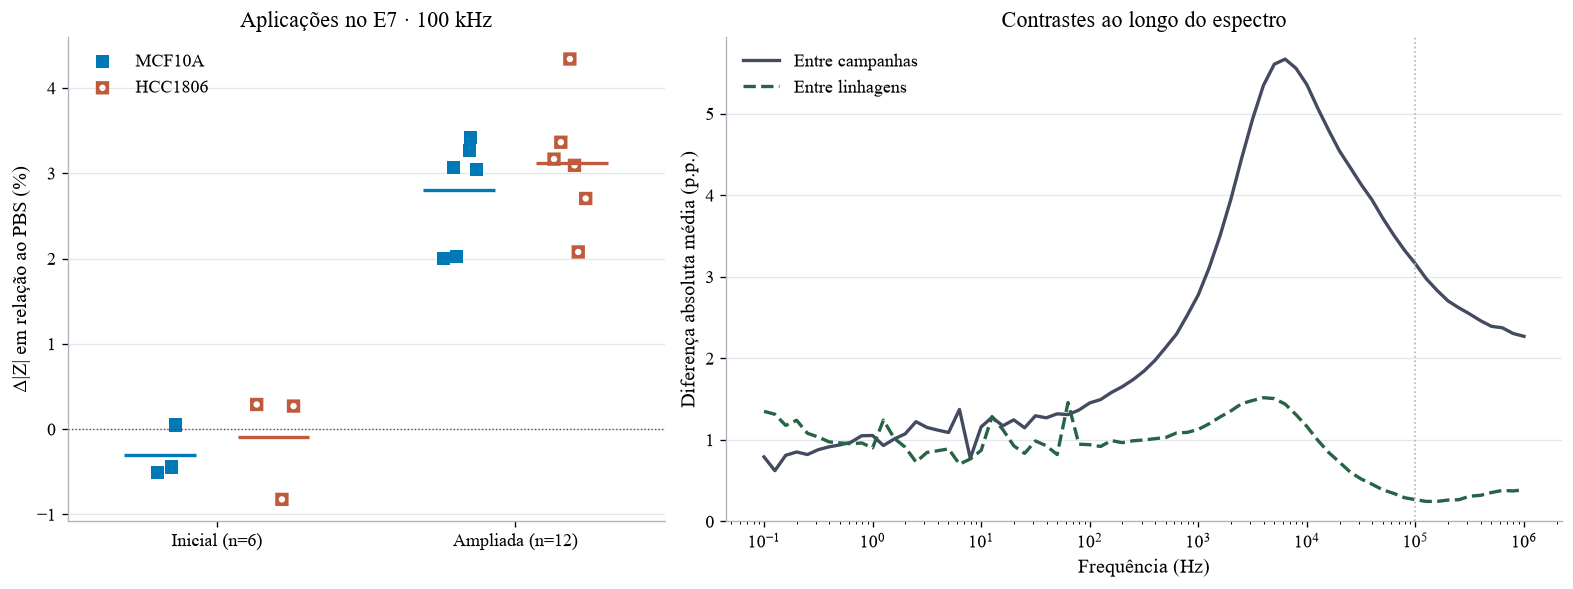

gotas  media_pct  minimo_pct  maximo_pct
etapa    linhagem                                          
Ampliada MCF10A        6       2.80        2.00        3.42
         HCC1806       6       3.12        2.08        4.34
Inicial  MCF10A        3      -0.30       -0.51        0.05
         HCC1806       3      -0.09       -0.82        0.29

Contraste entre campanhas maior em 59 de 71 frequências pela métrica de diferença absoluta média.


In [4]:
pbs_medio = (pbs.groupby(chaves, as_index=False).modulo_ohm.mean()
             .rename(columns={'modulo_ohm': 'pbs_medio'}))
normalizado = por_gota.merge(pbs_medio, on=chaves, how='left', validate='one_to_one')
assert normalizado.pbs_medio.notna().all(), 'Há dados de VEs sem PBS na mesma frequência.'
normalizado['delta_pct'] = 100 * (normalizado.media / normalizado.pbs_medio - 1)
em_100k = normalizado[normalizado.frequencia_hz.eq(FREQ)]
medias = normalizado.groupby(['frequencia_hz', 'etapa', 'linhagem']).delta_pct.mean().unstack(
    ['etapa', 'linhagem']
)
assert medias.shape == (71, 4) and medias.notna().all().all()
entre_campanhas = sum(
    (medias['Ampliada', linhagem] - medias['Inicial', linhagem]).abs()
    for linhagem in LINHAGENS
) / len(LINHAGENS)
entre_linhagens = sum(
    (medias[etapa, 'HCC1806'] - medias[etapa, 'MCF10A']).abs() for etapa in CAMPANHAS.values()
) / len(CAMPANHAS)

fig, (ax, freq_ax) = plt.subplots(1, 2, figsize=(13, 4.8), width_ratios=[1, 1.4])
rng = np.random.default_rng(42)
for x, etapa in enumerate(CAMPANHAS.values()):
    for dx, (linhagem, (cor, marcador)) in zip([-.19, .19], LINHAGENS.items()):
        valores = em_100k.loc[em_100k.etapa.eq(etapa) & em_100k.linhagem.eq(linhagem), 'delta_pct']
        pos = x + dx
        ax.scatter(pos + rng.uniform(-.07, .07, len(valores)), valores, color=cor,
                   marker=marcador, s=64, edgecolors='none', label=linhagem if x == 0 else None)
        ax.hlines(valores.mean(), pos - .12, pos + .12, color=cor, lw=2)
ax.axhline(0, color=CINZA, ls=':', lw=.8)
ax.set_xticks([0, 1], ['Inicial (n=6)', 'Ampliada (n=12)'])
ax.set(xlim=(-.5, 1.5), title='Aplicações no E7 · 100 kHz', ylabel='Δ|Z| em relação ao PBS (%)')
ax.legend(frameon=False, loc='upper left')

freq_ax.semilogx(entre_campanhas.index, entre_campanhas, color=CINZA, lw=2, label='Entre campanhas')
freq_ax.semilogx(entre_linhagens.index, entre_linhagens, color=VERDE, lw=2, ls='--',
                 label='Entre linhagens')
freq_ax.axvline(FREQ, color='#ABB5BD', lw=1, ls=':')
freq_ax.set(title='Contrastes ao longo do espectro', xlabel='Frequência (Hz)',
            ylabel='Diferença absoluta média (p.p.)', ylim=(0, None))
freq_ax.legend(frameon=False)
plt.show()
resumo = em_100k.groupby(['etapa', 'linhagem'], sort=False).delta_pct.agg(
    gotas='size', media_pct='mean', minimo_pct='min', maximo_pct='max',
)
display(resumo.round(2))
maior = entre_campanhas.gt(entre_linhagens)
print(f'Contraste entre campanhas maior em {maior.sum()} de {len(maior)} frequências '
      'pela métrica de diferença absoluta média.')

### Dispersão a 100 kHz nas quatro campanhas históricas

A figura mostra as 30 aplicações das campanhas 1 a 4, numeradas pela ordem em que as medições foram realizadas. Em cada aplicação, usamos a média das três leituras de |Z| da gota e a média das três leituras de |Z| do PBS de mesmo número na campanha. A variação é 100 × (média da gota / média do PBS − 1). Os traços horizontais representam a média das aplicações de cada linhagem dentro da campanha.

Este PDF tem largura de 16 cm e usa Times New Roman com 13 pt nos números, nomes das campanhas e legenda, 14 pt no rótulo do eixo Y e 15 pt no título.

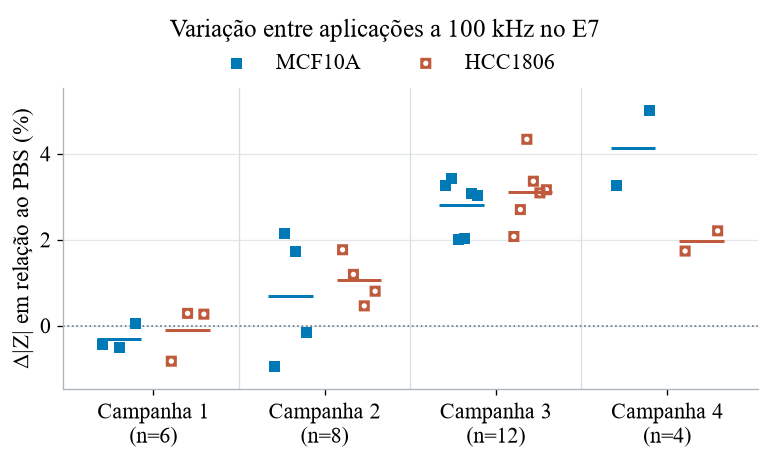

gotas  media_pct  min_pct  max_pct
etapa      linhagem                                    
Campanha 1 HCC1806       3      -0.09    -0.82     0.29
           MCF10A        3      -0.30    -0.51     0.05
Campanha 2 HCC1806       4       1.06     0.46     1.77
           MCF10A        4       0.70    -0.94     2.15
Campanha 3 HCC1806       6       3.12     2.08     4.34
           MCF10A        6       2.80     2.00     3.42
Campanha 4 HCC1806       2       1.97     1.74     2.21
           MCF10A        2       4.13     3.25     5.00

In [ ]:
ves_100k = (ves[ves.frequencia_hz.eq(FREQ)]
            .groupby(['etapa', 'gota', 'linhagem'], as_index=False).modulo_ohm.mean())
pbs_100k = (pbs[pbs.frequencia_hz.eq(FREQ)]
            .groupby(['etapa', 'gota'], as_index=False).modulo_ohm.mean()
            .rename(columns={'modulo_ohm': 'pbs_ohm'}))
dados_100k = ves_100k.merge(pbs_100k, on=['etapa', 'gota'], how='left', validate='one_to_one')
assert len(dados_100k) == 30 and dados_100k.pbs_ohm.notna().all()
dados_100k['delta_pct'] = 100 * (dados_100k.modulo_ohm / dados_100k.pbs_ohm - 1)
etapas = {
    'Inicial': 'Campanha 1',
    'T01–T08': 'Campanha 2',
    'Ampliada': 'Campanha 3',
    'Validação': 'Campanha 4',
}
resumo_100k = (dados_100k.groupby(['etapa', 'linhagem']).delta_pct
              .agg(gotas='size', media_pct='mean', min_pct='min', max_pct='max'))
assert resumo_100k.gotas.groupby('etapa').sum().to_dict() == {
    'Inicial': 6, 'T01–T08': 8, 'Ampliada': 12, 'Validação': 4,
}

with plt.rc_context({'font.size': 13, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
                     'axes.labelsize': 14, 'legend.fontsize': 13, 'legend.title_fontsize': 15}):
    fig, ax = plt.subplots(figsize=(16 / 2.54, 9.6 / 2.54))
    rotulos = []
    for i, (etapa, nome) in enumerate(etapas.items()):
        grupo = dados_100k[dados_100k.etapa.eq(etapa)]
        rotulos.append(f'{nome}\n(n={len(grupo)})')
        for dx, (linhagem, (cor, marcador)) in zip([-.20, .20], LINHAGENS.items()):
            valores = grupo.loc[grupo.linhagem.eq(linhagem), 'delta_pct']
            pos = i + dx
            ax.hlines(valores.mean(), pos - .13, pos + .13, color=cor, lw=1.8)
            ax.scatter(pos + np.linspace(-.095, .095, len(valores)), valores,
                       color=cor, marker=marcador, s=44, edgecolors='none', zorder=3,
                       label=linhagem if i == 0 else None)
    ax.axhline(0, color='#667785', ls=':', lw=1)
    for divisa in (.5, 1.5, 2.5):
        ax.axvline(divisa, color='#D8DEE3', lw=.8, zorder=0)
    ax.set_xticks(range(len(etapas)), rotulos)
    ax.set(xlim=(-.53, 3.53), ylabel='Δ|Z| em relação ao PBS (%)')
    ax.margins(y=.09)
    fig.legend(*ax.get_legend_handles_labels(), loc='outside upper center', ncol=2,
               frameon=False, title='Variação entre aplicações a 100 kHz no E7')
    fig.savefig(PASTA_FIGURAS / 'e7_variacao_100khz_quatro_campanhas.pdf')
    plt.show()
display(resumo_100k.reindex(etapas, level='etapa').rename(index=etapas, level='etapa').round(2))

## Leitura para a discussão

A dispersão das três aquisições indica a estabilidade imediata da leitura. O deslocamento entre as campanhas do E7 ajuda a motivar a avaliação dos classificadores em campanhas e eletrodos deixados de fora do treinamento. Para relacionar esse deslocamento aos erros, é preciso vincular as previsões a cada aplicação e conferir as divisões usadas nos modelos.